In [1]:
%pip install openpyxl

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.2.1
[notice] To update, run: C:\Users\User\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [2]:
%pip install numpy pandas matplotlib geopandas rasterio scipy

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.2.1
[notice] To update, run: C:\Users\User\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


# Punto 3 – Caracterización espacial de la precipitación observada
**Trabajo 1 de Hidroclimatología · Cuenca del río Cauca hasta Hidroituango**

Datos: promedios climatológicos 1981–2010 del IDEAM (hoja `Lluvia`).

| Paso del enunciado | Sección del notebook |
|---|---|
| 1. Identificar las estaciones dentro de la cuenca y en su vecindario | Sección 3 |
| 2. Seleccionar las estaciones necesarias | Sección 4 |
| 3. Mapa de precipitación media anual multianual | Secciones 5 a 7 |
| 4. Superponer las estaciones usadas | Sección 7 |
| Explicar y justificar el método de interpolación | Secciones 5, 6 y 9 |

La sección 8 (mapas mensuales y ciclo anual) adelanta el punto 13.

**Archivos que deben estar en la misma carpeta de este notebook:**
- `Promedios_Climatologicos_1981_2010.xlsx` (el Excel del IDEAM, renombrado sin tildes ni paréntesis)
- `cuenca_cauca.gpkg` (polígono de la cuenca del punto 2, EPSG:3116)
- `DEM_cuenca.tif` (DEM recortado a la cuenca del punto 2, EPSG:3116)

## 0. Instalación de librerías
Ejecute esta celda **una sola vez**. Al terminar, reinicie el kernel con el botón *Restart* de la barra superior.

In [3]:
%pip install scipy numpy pandas matplotlib openpyxl geopandas rasterio

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.2.1
[notice] To update, run: C:\Users\User\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


## 1. Librerías y parámetros
Si sus archivos están en otra carpeta, ponga la ruta completa con una `r` delante, por ejemplo
`CUENCA = r"C:\...\cuenca_cauca.gpkg"`.

In [4]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import geopandas as gpd
import rasterio
from scipy.spatial import cKDTree
from scipy.spatial.distance import pdist
from scipy.optimize import curve_fit

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)

# ----------------------------- PARÁMETROS -----------------------------
EXCEL = "Promedios_Climatologicos_1981_2010.xlsx"
HOJA = "Lluvia"
CUENCA = "cuenca_cauca.gpkg"
DEM = "DEM_cuenca.tif"
CRS = "EPSG:3116"            # MAGNA-SIRGAS / Colombia Bogotá zone (el del DEM del curso)
BUFFER_KM = 25               # ancho del vecindario alrededor de la cuenca
ANUAL_DESDE = "meses"        # "meses" = suma de los 12 promedios mensuales | "anual" = columna ANUAL del IDEAM
METODO = "auto"              # "auto" (menor RMSE en validación cruzada), "idw" o "kriging"
IDW_POTENCIAS = [1, 2, 3]
VECINOS = 16                 # estaciones más cercanas usadas en cada estimación
MODELOS_KRIGING = ["esferico", "exponencial", "gaussiano"]
NODATA = -9999.0
# ----------------------------------------------------------------------

MESES = ["ENE", "FEB", "MAR", "ABR", "MAY", "JUN", "JUL", "AGO", "SEP", "OCT", "NOV", "DIC"]

## 2. Lectura del Excel y control de calidad
- Las coordenadas vienen en grados-minutos-segundos (`75°39'48.7"W`) y se convierten a grados decimales.
- Se quitan las filas de "Convenciones" del final de la hoja.
- Las estaciones con coordenadas repetidas se promedian, porque vuelven singular el sistema del kriging.
- La columna `ANUAL` del IDEAM se calcula solo con años completos, así que no es exactamente la suma de los meses.
  Por defecto se usa la **suma de los 12 meses**, para que el mapa anual sea coherente con los mapas mensuales.

In [5]:
def dms_a_decimal(texto):
    # '75°39'48.7"W' -> -75.6635 ; acepta coma o punto decimal; W, O y S son negativos
    m = re.match(r'^\s*(\d+)\s*[°º]\s*(\d+)\s*\'\s*([\d.,]+)\s*"?\s*([NSWEO])', str(texto))
    if m is None:
        return np.nan
    g, mi, s, h = m.groups()
    v = int(g) + int(mi) / 60 + float(s.replace(",", ".")) / 3600
    return -v if h in "SWO" else v


df = pd.read_excel(EXCEL, sheet_name=HOJA, header=1, usecols=range(21))
df = df[pd.to_numeric(df["CODIGO"], errors="coerce").notna()].copy()
df["CODIGO"] = df["CODIGO"].astype(int)
df["ZONA_HIDRO"] = df["CODIGO"].astype(str).str.zfill(8).str[:2]
df["lon"] = df["LONGITUD"].map(dms_a_decimal)
df["lat"] = df["LATITUD"].map(dms_a_decimal)
print("Coordenadas que no se pudieron leer:", df[["lon", "lat"]].isna().any(axis=1).sum())
df = df.dropna(subset=["lon", "lat"] + MESES)

suma = df[MESES].sum(axis=1)
dif = (suma - df["ANUAL"]) / df["ANUAL"] * 100
print(f"Estaciones: {len(df)}")
print(f"Diferencia entre suma de meses y ANUAL: media {dif.mean():.2f} %, máxima {dif.abs().max():.1f} %")
df["P_ANUAL"] = suma if ANUAL_DESDE == "meses" else df["ANUAL"]

num = MESES + ["P_ANUAL", "ELEV", "ANUAL"]
dup = df.duplicated(["lon", "lat"], keep=False)
if dup.any():
    print(f"{dup.sum()} estaciones con coordenadas repetidas (se promedian):")
    display(df.loc[dup, ["CODIGO", "NOMBRE", "MUNICIPIO", "lon", "lat", "P_ANUAL"]])
    agg = {c: "first" for c in df.columns if c not in num}
    agg.update({c: "mean" for c in num})
    df = df.groupby(["lon", "lat"], as_index=False).agg(agg)
df = df.reset_index(drop=True)
df[["CODIGO", "CAT", "NOMBRE", "MUNICIPIO", "DEPARTAMENTO", "ELEV", "lon", "lat", "P_ANUAL"]].head()

Coordenadas que no se pudieron leer: 0
Estaciones: 2046
Diferencia entre suma de meses y ANUAL: media 0.71 %, máxima 11.7 %
4 estaciones con coordenadas repetidas (se promedian):


,CODIGO,NOMBRE,MUNICIPIO,lon,lat,P_ANUAL
1433,16050160,Llano Suarez,Abrego,-73.233333,8.050000,1265.934625
1435,16050090,Teja La,Abrego,-73.233333,8.050000,1145.244859
1875,21180210,Valle de San Juan,Valle de San Juan,-75.104444,4.216944,1590.859392
1876,21185080,Valle de San Juan,Valle de San Juan,-75.104444,4.216944,1483.590909


,CODIGO,CAT,NOMBRE,MUNICIPIO,DEPARTAMENTO,ELEV,lon,lat,P_ANUAL
0,17010020,PM,Hoyo Soplador,San Andres,San Andres Providencia y Sta C,2.0,-81.730444,12.481000,1887.092279
1,17010010,PG,Empoislas,San Andres,San Andres Providencia y Sta C,80.0,-81.720250,12.539750,2012.966127
2,17015010,RS,Apto Sesquicen-Aut,San Andres,San Andres Providencia y Sta C,1.0,-81.703889,12.586944,1985.563333
3,17020030,PM,San Felipe,Providencia,San Andres Providencia y Sta C,12.0,-81.391444,13.356444,2054.019768
4,17020040,PM,Agua Dulce,Providencia,San Andres Providencia y Sta C,95.0,-81.388111,13.343778,1945.723518


## 3. Identificación de estaciones dentro de la cuenca y en su vecindario
- **dentro**: la estación cae dentro del polígono de la cuenca.
- **vecindario**: está a menos de `BUFFER_KM` km del límite. Sirve para que la interpolación no extrapole en los bordes.
- Se incluyen todas las estaciones dentro del búfer, también las de la vertiente del Pacífico.

Área de la cuenca: 35,283 km²
ubicacion
dentro        250
vecindario    121
Densidad dentro de la cuenca: 7.1 estaciones por cada 1.000 km²


ubicacion,dentro,vecindario
Zona hidrográfica (código IDEAM),,
11,1,13
21,0,29
22,0,3
23,0,14
26,246,17
27,2,11
52,0,9
53,0,8
54,1,17


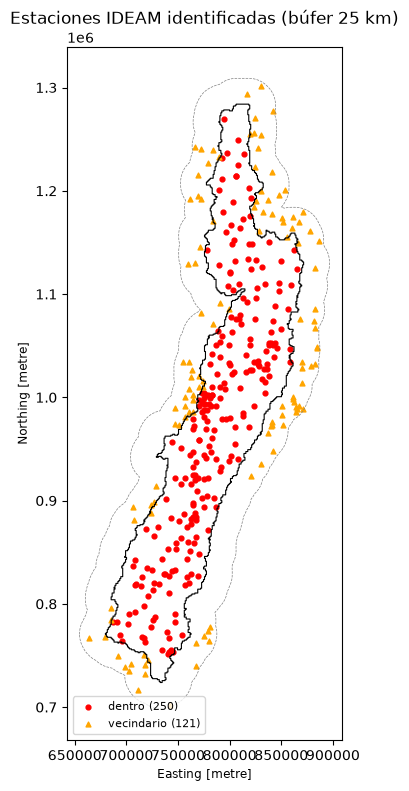

In [6]:
est = gpd.GeoDataFrame(df, geometry=gpd.points_from_xy(df.lon, df.lat), crs="EPSG:4326").to_crs(CRS)
cuenca = gpd.read_file(CUENCA).to_crs(CRS)
poli = cuenca.union_all() if hasattr(cuenca, "union_all") else cuenca.unary_union
area_km2 = poli.area / 1e6

dentro = est.within(poli)
dentro_buffer = est.within(poli.buffer(BUFFER_KM * 1000))
vecino = dentro_buffer & ~dentro
est["ubicacion"] = np.select([dentro, vecino], ["dentro", "vecindario"], "fuera")

ident = est[est.ubicacion != "fuera"].copy()
print(f"Área de la cuenca: {area_km2:,.0f} km²")
print(ident.ubicacion.value_counts().to_string())
print(f"Densidad dentro de la cuenca: {dentro.sum() / area_km2 * 1000:.1f} estaciones por cada 1.000 km²")
display(pd.crosstab(ident.ZONA_HIDRO, ident.ubicacion).rename_axis("Zona hidrográfica (código IDEAM)"))

fig, ax = plt.subplots(figsize=(6, 9))
cuenca.boundary.plot(ax=ax, color="k", lw=0.8)
gpd.GeoSeries([poli.buffer(BUFFER_KM * 1000)], crs=CRS).boundary.plot(ax=ax, color="gray", lw=0.5, ls="--")
estilos = {"dentro": ("o", "red"), "vecindario": ("^", "orange")}
for u, (mk, col) in estilos.items():
    s = ident[ident.ubicacion == u]
    ax.scatter(s.geometry.x, s.geometry.y, marker=mk, s=12, color=col, label=f"{u} ({len(s)})")
ax.set_title(f"Estaciones IDEAM identificadas (búfer {BUFFER_KM} km)")
ax.legend(loc="lower left", fontsize=8)
ax.set_aspect("equal")
plt.show()

## 4. Selección de estaciones
Se usan las estaciones **dentro** y del **vecindario**. La tabla de abajo muestra la precipitación según la ubicación;
sirve para describir la red de estaciones en el informe. Las estaciones se guardan para cargarlas en QGIS.

In [7]:
sel = ident[ident.ubicacion.isin(["dentro", "vecindario"])].copy()
sel["x"], sel["y"] = sel.geometry.x, sel.geometry.y
xy = np.c_[sel.x, sel.y] / 1000.0          # coordenadas en km
z = sel["P_ANUAL"].to_numpy(float)

display(sel.groupby("ubicacion")["P_ANUAL"].describe().round(0))
display(sel.groupby("ubicacion")["ELEV"].describe().round(0))
print("Estaciones más secas y más lluviosas usadas:")
display(sel.sort_values("P_ANUAL").iloc[np.r_[0:3, -3:0]][["CODIGO", "NOMBRE", "MUNICIPIO", "ELEV", "ubicacion", "P_ANUAL"]].round(0))

ident.drop(columns="geometry").to_csv("estaciones_P_identificadas.csv", index=False, encoding="utf-8-sig")

,count,mean,std,min,25%,50%,75%,max
ubicacion,,,,,,,,
dentro,250.0,1911.0,580.0,852.0,1460.0,1891.0,2343.0,3506.0
vecindario,121.0,2298.0,1267.0,896.0,1481.0,1936.0,2542.0,7356.0


,count,mean,std,min,25%,50%,75%,max
ubicacion,,,,,,,,
dentro,250.0,1570.0,627.0,530.0,1024.0,1500.0,1946.0,4150.0
vecindario,121.0,1874.0,593.0,370.0,1500.0,1870.0,2200.0,3740.0


Estaciones más secas y más lluviosas usadas:


,CODIGO,NOMBRE,MUNICIPIO,ELEV,ubicacion,P_ANUAL
431,26100660,Bancos Los,Tulua,2350.0,dentro,852.0
252,26075040,Apto A Bonilla,Palmira,961.0,dentro,888.0
260,54030020,Naranjal,Bolivar,1143.0,vecindario,896.0
359,54010030,Sta Cecilia,Pueblo Rico,370.0,vecindario,6457.0
673,26230160,Briceno,Brice#O,1440.0,vecindario,6528.0
287,11020050,Pinon El,El Carmen de Atrato,715.0,vecindario,7356.0


## 5. Métodos de interpolación
**IDW (inverso de la distancia ponderado):** el valor en cada punto es un promedio de las estaciones cercanas,
con pesos $w_i = 1/d_i^{\,p}$. A mayor potencia $p$, más peso tienen las estaciones más cercanas.

**Kriging ordinario:** los pesos salen de un modelo de semivariograma $\gamma(h)$, que describe cuánto se parecen dos
estaciones según la distancia $h$ que las separa. Los pesos cumplen $\sum w_i = 1$ y minimizan la varianza del error.
Se prueban tres modelos de semivariograma (con pepita $c_0$, meseta parcial $c$ y rango práctico $a$):

- Esférico: $\gamma(h) = c_0 + c\left[1.5\frac{h}{a} - 0.5\left(\frac{h}{a}\right)^3\right]$ para $h<a$
- Exponencial: $\gamma(h) = c_0 + c\left[1 - e^{-3h/a}\right]$
- Gaussiano: $\gamma(h) = c_0 + c\left[1 - e^{-3h^2/a^2}\right]$

Ambos métodos usan las `VECINOS` estaciones más cercanas a cada celda.

In [8]:
def idw(xy, z, xy0, p=2, k=VECINOS):
    k = min(k, len(z))
    d, i = cKDTree(xy).query(xy0, k)
    d = np.maximum(d, 1e-9)
    w = 1.0 / d ** p
    return (w * z[i]).sum(1) / w.sum(1)


def _esferico(h, c0, c, a):
    h = np.asarray(h, float)
    return np.where(h < a, c0 + c * (1.5 * h / a - 0.5 * (h / a) ** 3), c0 + c)

def _exponencial(h, c0, c, a):
    return c0 + c * (1 - np.exp(-3 * np.asarray(h, float) / a))

def _gaussiano(h, c0, c, a):
    return c0 + c * (1 - np.exp(-3 * (np.asarray(h, float) / a) ** 2))

MODELOS = {"esferico": _esferico, "exponencial": _exponencial, "gaussiano": _gaussiano}


def semivariograma_empirico(xy, z, n_lags=15):
    d = pdist(xy)
    g = 0.5 * pdist(z[:, None], "sqeuclidean")
    bordes = np.linspace(0, d.max() / 2, n_lags + 1)
    idx = np.digitize(d, bordes) - 1
    h, gam, n = [], [], []
    for k in range(n_lags):
        s = idx == k
        if s.sum() >= 10:
            h.append(d[s].mean()); gam.append(g[s].mean()); n.append(s.sum())
    return np.array(h), np.array(gam), np.array(n)


def ajustar_semivariograma(xy, z, modelo):
    h, gam, n = semivariograma_empirico(xy, z)
    var = z.var()
    par, _ = curve_fit(MODELOS[modelo], h, gam, p0=[0.1 * var, 0.9 * var, h.max() / 2],
                       bounds=([0, 0, h[0]], [2 * var, 3 * var, 3 * h.max()]),
                       sigma=1 / np.sqrt(n), maxfev=20000)
    return par, (h, gam, n)


def kriging_ordinario(xy, z, xy0, modelo, par, k=VECINOS, bloque=4000):
    f = MODELOS[modelo]
    gamma = lambda h: np.where(h > 0, f(h, *par), 0.0)
    k = min(k, len(z))
    arbol = cKDTree(xy)
    est_, var_ = np.empty(len(xy0)), np.empty(len(xy0))
    for i0 in range(0, len(xy0), bloque):
        p = xy0[i0:i0 + bloque]; m = len(p)
        d0, idx = arbol.query(p, k)
        P = xy[idx]
        D = np.linalg.norm(P[:, :, None, :] - P[:, None, :, :], axis=-1)
        A = np.ones((m, k + 1, k + 1)); A[:, :k, :k] = gamma(D); A[:, k, k] = 0.0
        b = np.ones((m, k + 1)); b[:, :k] = gamma(d0)
        w = np.linalg.solve(A, b[..., None])[..., 0]
        est_[i0:i0 + m] = (w[:, :k] * z[idx]).sum(1)
        var_[i0:i0 + m] = (w * b).sum(1)
    return est_, var_

## 6. Semivariograma de la precipitación media anual
Fíjese en dos cosas para el informe:
- **La pepita**, es decir, el valor de $\gamma$ cerca de $h = 0$. Si es alta, hay mucha variación entre estaciones
  cercanas: efecto orográfico, microclimas o errores de medición.
- **Si la curva se estabiliza en una meseta o sigue creciendo.** Si sigue creciendo, hay una **tendencia regional**:
  del valle geográfico seco (≈ 900 mm) al norte muy húmedo cerca de Hidroituango (> 5.000 mm).

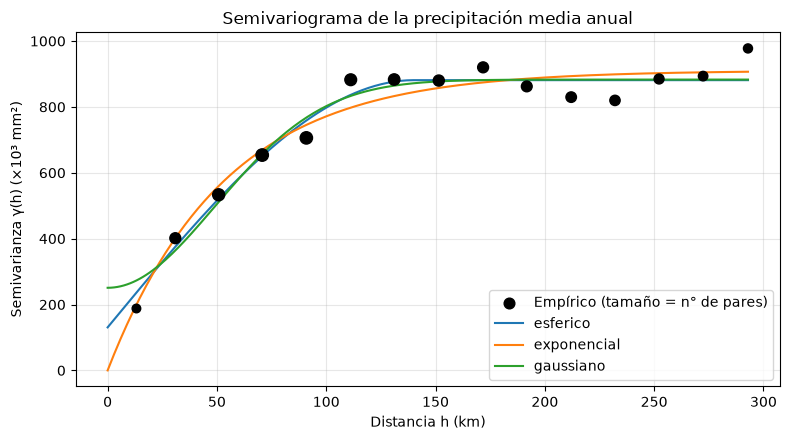

,modelo,pepita_mm2,meseta_total_mm2,pepita/meseta_%,rango_km
0,esferico,130621.3,881209.2,14.8,140.1
1,exponencial,0.0,910498.2,0.0,159.7
2,gaussiano,250814.4,882969.1,28.4,120.7


In [9]:
pars = {}
for mod in MODELOS_KRIGING:
    try:
        pars[mod] = ajustar_semivariograma(xy, z, mod)
    except RuntimeError:
        print(f"No se pudo ajustar el modelo {mod}")

h, g, n = semivariograma_empirico(xy, z)
hh = np.linspace(0, h.max(), 200)
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.scatter(h, g / 1e3, color="k", s=20 + n / n.max() * 60, label="Empírico (tamaño = n° de pares)", zorder=3)
filas = []
for mod, (par, _) in pars.items():
    ax.plot(hh, MODELOS[mod](hh, *par) / 1e3, label=mod)
    filas.append({"modelo": mod, "pepita_mm2": par[0], "meseta_total_mm2": par[0] + par[1],
                  "pepita/meseta_%": 100 * par[0] / (par[0] + par[1]), "rango_km": par[2]})
ax.set_xlabel("Distancia h (km)")
ax.set_ylabel("Semivarianza γ(h) (×10³ mm²)")
ax.set_title("Semivariograma de la precipitación media anual")
ax.grid(alpha=0.3); ax.legend()
fig.tight_layout(); fig.savefig("fig_semivariograma.png", dpi=200)
plt.show()
pd.DataFrame(filas).round(1)

## 7. Validación cruzada y elección del método
**Validación cruzada dejando una estación por fuera:** se saca una estación, se estima su valor con las demás
y se compara con lo observado. Esto se repite para todas las estaciones. El método con menor RMSE es el que mejor
reproduce la lluvia donde no hay estación; con eso se justifica la elección.

- $RMSE = \sqrt{\frac{1}{n}\sum (\hat P_i - P_i)^2}$
- $MAE = \frac{1}{n}\sum |\hat P_i - P_i|$
- $Sesgo = \frac{1}{n}\sum (\hat P_i - P_i)$

Método seleccionado: Kriging exponencial


,metodo,RMSE_mm,MAE_mm,Sesgo_mm,r
0,Kriging exponencial,562.96,330.83,-14.28,0.77
1,Kriging esferico,563.60,337.02,-11.98,0.77
2,Kriging gaussiano,590.99,367.39,-8.49,0.74
3,IDW p=3,592.56,342.53,-37.99,0.74
4,IDW p=2,597.45,342.36,-47.05,0.74
5,IDW p=1,631.21,365.69,-61.76,0.71


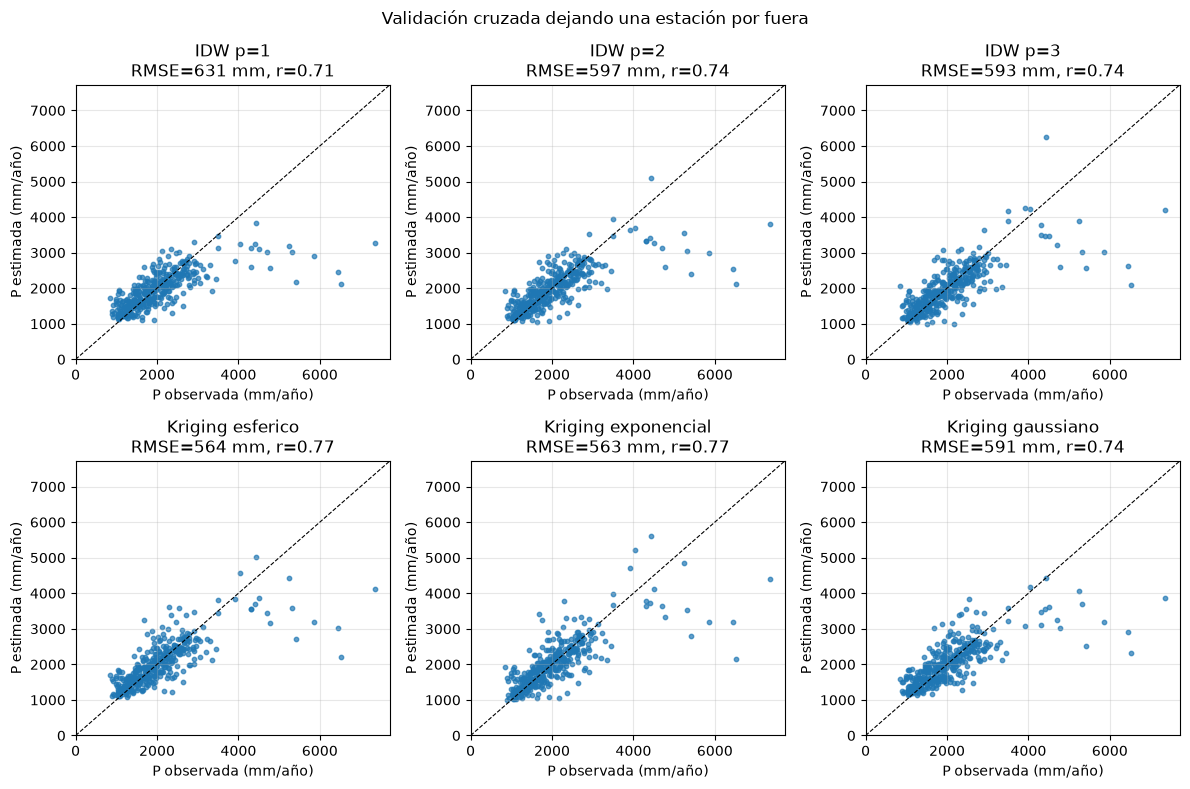

In [10]:
def validacion_cruzada(metodo, **kw):
    pred = np.empty(len(z))
    for i in range(len(z)):
        m = np.ones(len(z), bool); m[i] = False
        if metodo == "idw":
            pred[i] = idw(xy[m], z[m], xy[i:i + 1], p=kw["p"])[0]
        else:
            pred[i] = kriging_ordinario(xy[m], z[m], xy[i:i + 1], kw["modelo"], kw["par"])[0][0]
    return pred


def metricas(obs, pred):
    e = pred - obs
    return {"RMSE_mm": np.sqrt(np.mean(e ** 2)), "MAE_mm": np.mean(np.abs(e)),
            "Sesgo_mm": e.mean(), "r": np.corrcoef(obs, pred)[0, 1]}


preds, filas = {}, []
for p in IDW_POTENCIAS:
    preds[f"IDW p={p}"] = validacion_cruzada("idw", p=p)
for mod, (par, _) in pars.items():
    preds[f"Kriging {mod}"] = validacion_cruzada("kriging", modelo=mod, par=par)
tabla_cv = pd.DataFrame([{"metodo": k, **metricas(z, v)} for k, v in preds.items()]).sort_values("RMSE_mm")
tabla_cv = tabla_cv.reset_index(drop=True)

if METODO == "idw":
    metodo = tabla_cv[tabla_cv.metodo.str.startswith("IDW")].metodo.iloc[0]
elif METODO == "kriging":
    metodo = tabla_cv[tabla_cv.metodo.str.startswith("Kriging")].metodo.iloc[0]
else:
    metodo = tabla_cv.metodo.iloc[0]
print("Método seleccionado:", metodo)
tabla_cv.round(3).to_csv("validacion_cruzada_metodos.csv", index=False)
display(tabla_cv.round(2))

nc = (len(preds) + 1) // 2
fig, axs = plt.subplots(2, nc, figsize=(4 * nc, 8), squeeze=False)
lim = [0, max(z.max(), max(v.max() for v in preds.values())) * 1.05]
for ax, (nom, v) in zip(axs.ravel(), preds.items()):
    r = tabla_cv.set_index("metodo").loc[nom]
    ax.scatter(z, v, s=10, alpha=0.7)
    ax.plot(lim, lim, "k--", lw=0.8)
    ax.set(xlim=lim, ylim=lim, title=f"{nom}\nRMSE={r.RMSE_mm:.0f} mm, r={r.r:.2f}",
           xlabel="P observada (mm/año)", ylabel="P estimada (mm/año)")
    ax.grid(alpha=0.3)
for ax in axs.ravel()[len(preds):]:
    ax.axis("off")
fig.suptitle("Validación cruzada dejando una estación por fuera")
fig.tight_layout(); fig.savefig("fig_validacion_cruzada.png", dpi=200)
plt.show()

### Estaciones con mayor error en la validación cruzada
Pueden ser **núcleos reales de lluvia** (por ejemplo, Briceño, cerca de Hidroituango) o **datos dudosos**.
Revíselas: si tiene argumentos para quitar alguna, agregue su código a `QUITAR` y vuelva a correr desde la sección 4.

In [11]:
sel["P_estimada_LOO"] = preds[metodo]
sel["residuo_LOO"] = sel["P_estimada_LOO"] - sel["P_ANUAL"]
peores = sel.reindex(sel["residuo_LOO"].abs().sort_values(ascending=False).index).head(10)
display(peores[["CODIGO", "NOMBRE", "MUNICIPIO", "ELEV", "ubicacion", "P_ANUAL", "P_estimada_LOO", "residuo_LOO"]].round(0))

QUITAR = []   # p.ej. [26230160]; luego vuelva a correr desde la sección 4 filtrando: sel = sel[~sel.CODIGO.isin(QUITAR)]

cols = ["CODIGO", "ZONA_HIDRO", "CAT", "NOMBRE", "MUNICIPIO", "DEPARTAMENTO", "ELEV", "lon", "lat", "x", "y",
        "ubicacion", "P_ANUAL", "P_estimada_LOO", "residuo_LOO"] + MESES
sel[cols].round(2).to_csv("estaciones_P_seleccionadas.csv", index=False, encoding="utf-8-sig")
sel[cols + ["geometry"]].to_file("estaciones_P_seleccionadas.gpkg", driver="GPKG")
print("Guardado: estaciones_P_seleccionadas.csv y .gpkg (cárguelas en QGIS para el mapa final)")

,CODIGO,NOMBRE,MUNICIPIO,ELEV,ubicacion,P_ANUAL,P_estimada_LOO,residuo_LOO
673,26230160,Briceno,Brice#O,1440.0,vecindario,6528.0,2139.0,-4389.0
359,54010030,Sta Cecilia,Pueblo Rico,370.0,vecindario,6457.0,3184.0,-3273.0
287,11020050,Pinon El,El Carmen de Atrato,715.0,vecindario,7356.0,4414.0,-2942.0
120,53070080,Veinte de Julio,El Tambo,2200.0,vecindario,5864.0,3193.0,-2672.0
310,54020050,Sinai El,San Jose del Palmar,1870.0,vecindario,5421.0,2798.0,-2623.0
872,23055070,Argelia,Argelia,1669.0,vecindario,5304.0,3516.0,-1787.0
586,26235030,Matanzas,Toledo,500.0,vecindario,1684.0,3408.0,1723.0
410,54015010,Pueblo Rico,Pueblo Rico,1530.0,vecindario,2284.0,3787.0,1503.0
307,54030160,Cairo El,El Cairo,1850.0,vecindario,1755.0,3248.0,1494.0
433,54010060,Pto de Oro,Mistrato,820.0,vecindario,4766.0,3328.0,-1437.0


Guardado: estaciones_P_seleccionadas.csv y .gpkg (cárguelas en QGIS para el mapa final)


## 8. Mapa de precipitación media anual multianual
La interpolación se hace sobre la misma grilla del `DEM_cuenca.tif` (≈ 930 m). Así este mapa queda alineado
con los de temperatura, ETP y ETR de los puntos 5 a 7.

Celdas de la cuenca: 40,633  (tamaño de celda 932 m)
Método: Kriging exponencial
P media anual de la cuenca: 1,990 mm/año  (mín 856, máx 5,421)
Volumen medio anual precipitado: 70.2 km³/año


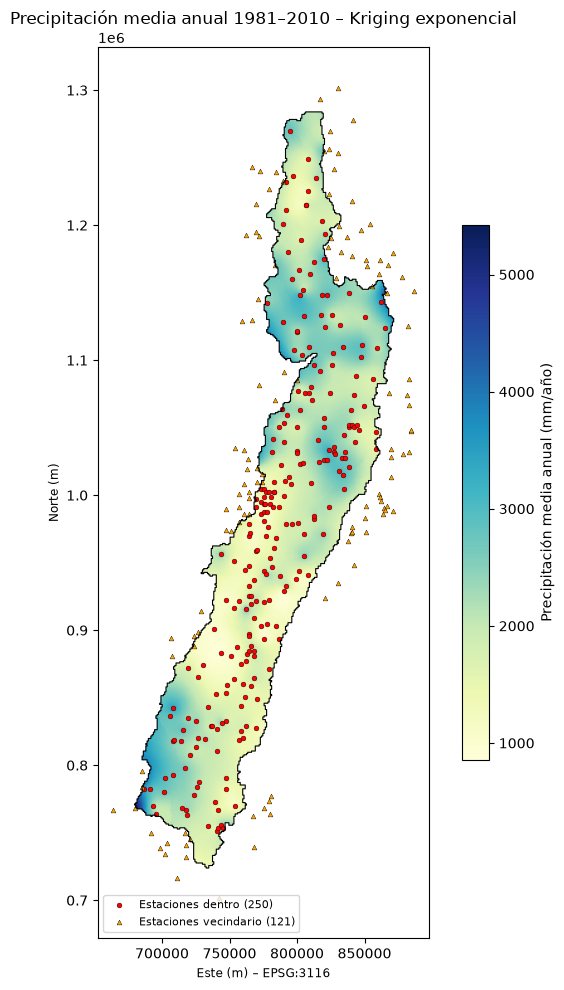

In [12]:
with rasterio.open(DEM) as src:
    dem = src.read(1, masked=True)
    perfil = src.profile.copy()
    T = src.transform
filas_g, cols_g = np.nonzero(~np.ma.getmaskarray(dem))
xs, ys = rasterio.transform.xy(T, filas_g, cols_g, offset="center")
xy0 = np.c_[xs, ys] / 1000.0
perfil.update(dtype="float32", nodata=NODATA, compress="lzw", crs=CRS, count=1)
print(f"Celdas de la cuenca: {len(xy0):,}  (tamaño de celda {T.a:.0f} m)")


def interpolar(nombre, valores, modelo_fijo=None):
    if nombre.startswith("IDW"):
        return idw(xy, valores, xy0, p=int(nombre.split("=")[1]))
    mod = modelo_fijo or nombre.split()[1]
    try:
        par, _ = ajustar_semivariograma(xy, valores, mod)
    except RuntimeError:
        print("  El semivariograma no convergió; se usa IDW p=2 para esta variable.")
        return idw(xy, valores, xy0, p=2)
    return np.clip(kriging_ordinario(xy, valores, xy0, mod, par)[0], 0, None)


def a_raster(v):
    r = np.full(dem.shape, NODATA, dtype="float32")
    r[filas_g, cols_g] = v
    return r


P_anual = interpolar(metodo, z)
with rasterio.open("P_IDEAM_anual.tif", "w", **perfil) as dst:
    dst.write(a_raster(P_anual), 1)

print(f"Método: {metodo}")
print(f"P media anual de la cuenca: {P_anual.mean():,.0f} mm/año  (mín {P_anual.min():,.0f}, máx {P_anual.max():,.0f})")
print(f"Volumen medio anual precipitado: {P_anual.mean() / 1000 * area_km2 * 1e6 / 1e9:,.1f} km³/año")

ext = [T.c, T.c + T.a * dem.shape[1], T.f + T.e * dem.shape[0], T.f]
fig, ax = plt.subplots(figsize=(7, 10))
im = ax.imshow(np.ma.masked_equal(a_raster(P_anual), NODATA), extent=ext, cmap="YlGnBu")
cuenca.boundary.plot(ax=ax, color="k", lw=0.8)
for u, (mk, col) in [("dentro", ("o", "red")), ("vecindario", ("^", "orange"))]:
    s = sel[sel.ubicacion == u]
    ax.scatter(s.x, s.y, marker=mk, s=12, color=col, edgecolor="k", lw=0.3, label=f"Estaciones {u} ({len(s)})")
plt.colorbar(im, ax=ax, shrink=0.6, label="Precipitación media anual (mm/año)")
ax.set_title(f"Precipitación media anual 1981–2010 – {metodo}")
ax.set_xlabel("Este (m) – EPSG:3116"); ax.set_ylabel("Norte (m)")
ax.legend(loc="lower left", fontsize=8)
fig.tight_layout(); fig.savefig("fig_P_anual_preliminar.png", dpi=200)
plt.show()

## 9. (Adelanto del punto 13) Mapas mensuales y ciclo anual
Se interpolan los 12 meses con el mismo método. La suma de los 12 mapas debe parecerse al mapa anual.

Suma de los 12 meses: 2,001 mm/año  |  mapa anual: 1,990 mm/año


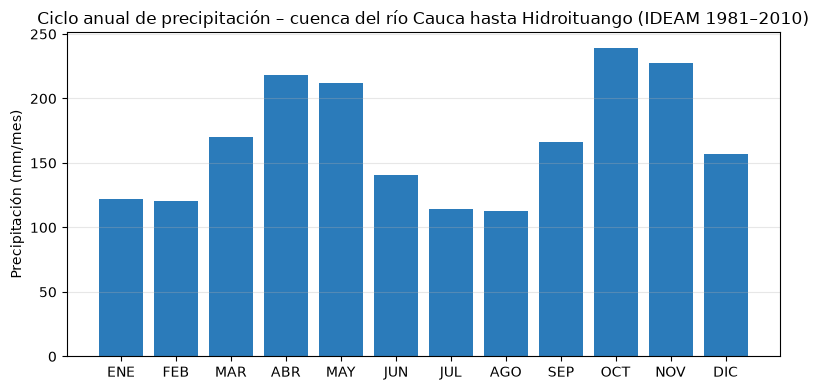

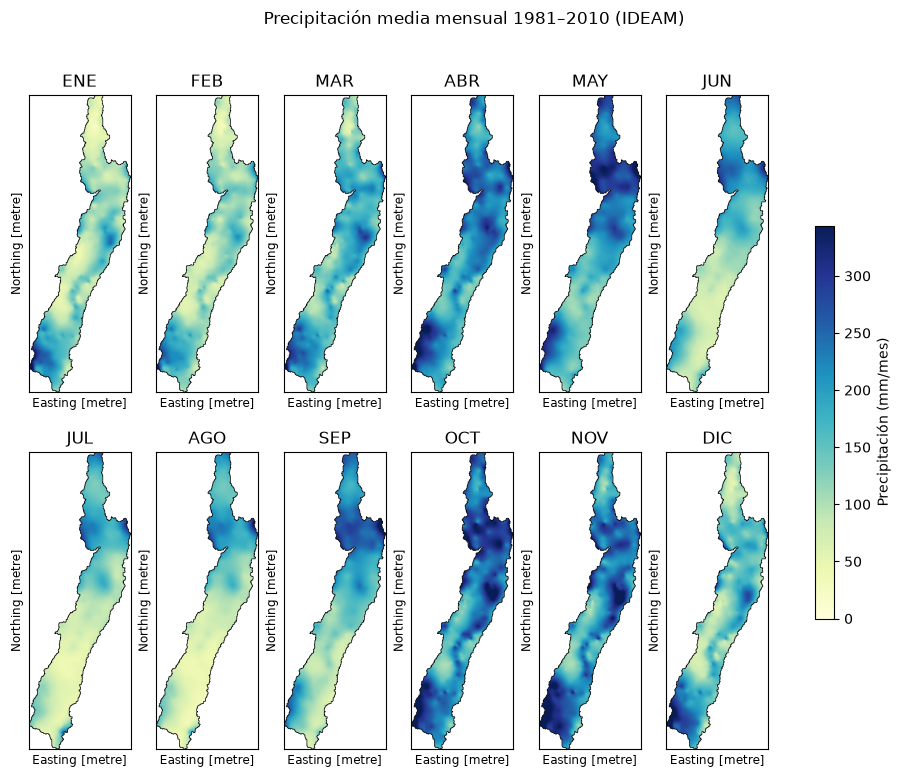

,mes,P_mm
0,ENE,121.9
1,FEB,120.7
2,MAR,169.8
3,ABR,218.1
4,MAY,212.0
5,JUN,140.8
6,JUL,114.6
7,AGO,112.9
8,SEP,166.5
9,OCT,239.3


In [13]:
mod_fijo = metodo.split()[1] if metodo.startswith("Kriging") else None
mensual, ciclo = [], []
for m in MESES:
    v = interpolar(metodo, sel[m].to_numpy(float), modelo_fijo=mod_fijo)
    mensual.append(a_raster(v)); ciclo.append(v.mean())

with rasterio.open("P_IDEAM_mensual.tif", "w", **{**perfil, "count": 12}) as dst:
    for b, arr in enumerate(mensual, start=1):
        dst.write(arr, b); dst.set_band_description(b, MESES[b - 1])
ciclo_df = pd.DataFrame({"mes": MESES, "P_mm": np.round(ciclo, 1)})
ciclo_df.to_csv("ciclo_anual_IDEAM.csv", index=False)
print(f"Suma de los 12 meses: {np.sum(ciclo):,.0f} mm/año  |  mapa anual: {P_anual.mean():,.0f} mm/año")

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(MESES, ciclo, color="#2b7bba")
ax.set_ylabel("Precipitación (mm/mes)")
ax.set_title("Ciclo anual de precipitación – cuenca del río Cauca hasta Hidroituango (IDEAM 1981–2010)")
ax.grid(axis="y", alpha=0.3)
fig.tight_layout(); fig.savefig("fig_ciclo_anual_IDEAM.png", dpi=200)
plt.show()

vmax = np.nanpercentile([np.ma.masked_equal(a, NODATA).compressed() for a in mensual], 99)
fig, axs = plt.subplots(2, 6, figsize=(12, 8.5))
for ax, m, arr in zip(axs.ravel(), MESES, mensual):
    im = ax.imshow(np.ma.masked_equal(arr, NODATA), extent=ext, cmap="YlGnBu", vmin=0, vmax=vmax)
    cuenca.boundary.plot(ax=ax, color="k", lw=0.5)
    ax.set_title(m); ax.set_xticks([]); ax.set_yticks([])
fig.colorbar(im, ax=axs, shrink=0.6, label="Precipitación (mm/mes)")
fig.suptitle("Precipitación media mensual 1981–2010 (IDEAM)")
fig.savefig("fig_P_mensual_12mapas.png", dpi=200)
plt.show()
ciclo_df

## 10. Datos para el informe
La siguiente celda imprime los números para completar este texto:

> Se usaron las normales climatológicas 1981–2010 del IDEAM. Se identificaron **[N dentro]** estaciones dentro de la
> cuenca y **[N vecindario]** adicionales dentro de un búfer de **[búfer]** km. Se incluyeron todas las estaciones
> del búfer, también las de la vertiente del Pacífico. Se compararon IDW (potencias 1 a 3) y kriging ordinario
> (modelos esférico, exponencial y gaussiano) mediante validación cruzada dejando una estación por fuera. Se seleccionó **[método]**, que tuvo el menor
> RMSE (**[RMSE]** mm/año, r = **[r]**). El semivariograma presenta una pepita de **[pepita/meseta]** % de la meseta
> y crece de forma continua con la distancia, lo que refleja una tendencia regional: del valle geográfico seco al
> norte muy húmedo cerca de Hidroituango. Ninguno de los dos métodos representa explícitamente el efecto orográfico;
> esto se reconoce como una fuente de incertidumbre en las zonas altas con pocas estaciones. La precipitación media
> anual de la cuenca resultó de **[P]** mm/año.

In [14]:
mejor = tabla_cv.set_index("metodo").loc[metodo]
cuenta = ident.ubicacion.value_counts()
print(f"N dentro: {cuenta.get('dentro', 0)} | N vecindario: {cuenta.get('vecindario', 0)} | búfer: {BUFFER_KM} km")
print(f"Método: {metodo} | RMSE: {mejor.RMSE_mm:.0f} mm/año | MAE: {mejor.MAE_mm:.0f} | "
      f"sesgo: {mejor.Sesgo_mm:.0f} | r: {mejor.r:.2f}")
for mod, (par, _) in pars.items():
    print(f"Semivariograma {mod}: pepita/meseta = {100 * par[0] / (par[0] + par[1]):.0f} %, rango = {par[2]:.0f} km")
print(f"P media anual de la cuenca: {P_anual.mean():,.0f} mm/año | Área: {area_km2:,.0f} km²")

N dentro: 250 | N vecindario: 121 | búfer: 25 km
Método: Kriging exponencial | RMSE: 563 mm/año | MAE: 331 | sesgo: -14 | r: 0.77
Semivariograma esferico: pepita/meseta = 15 %, rango = 140 km
Semivariograma exponencial: pepita/meseta = 0 %, rango = 160 km
Semivariograma gaussiano: pepita/meseta = 28 %, rango = 121 km
P media anual de la cuenca: 1,990 mm/año | Área: 35,283 km²
